# VisionGuard Medical — CalibrationMLP

Everything about the one network we trained from scratch.

**Sections**
1. Setup
2. Architecture + parameter count
3. The 8 input features
4. Training recipe
5. Loss curve + training accuracy
6. Live inference on three illustrative claims
7. First-layer weight heatmap
8. **Evaluation on 42 hand labels (test accuracy, confusion matrix, F1)**
9. **ROC curves and AUC (one-vs-rest)**
10. Honest limitations

*Not clinically validated. Research prototype only.*

## 1. Setup

In [1]:
import sys, pathlib, json, re, torch, torch.nn.functional as F, numpy as np, pandas as pd
import matplotlib.pyplot as plt
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
pd.set_option('display.max_colwidth', 50)
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
print('project root:', ROOT)

project root: D:\STUDY\DL Lab\Project\VisionGuard-Medical


## 2. Architecture + parameter count

In [2]:
from models.calibration import CalibrationMLP, FEATURE_NAMES, STATUS_INDEX, INDEX_STATUS, _IU_WEIGHTS
model = CalibrationMLP()
print(model)
print()
total = sum(p.numel() for p in model.parameters())
print(f'total parameters    : {total:,}')
print(f'trainable parameters: {total:,}')

CalibrationMLP(
  (net): Sequential(
    (0): Linear(in_features=8, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=3, bias=True)
  )
)

total parameters    : 9,603
trainable parameters: 9,603


## 3. The 8 input features

Each claim is reduced to this 8-dim vector before the MLP sees it.

In [3]:
descriptions = {
    'classifier_prob':             'torchxrayvision probability for the matching pathology',
    'classifier_abs_from_midpoint':'|classifier_prob - 0.5|  (confidence margin)',
    'detector_score':              'highest Grounding-DINO box score for the finding',
    'detector_present':            '1 if detector found any matching box, else 0',
    'polarity_is_negative':        '1 if claim is a negation ("no X"), else 0',
    'polarity_is_uncertain':       '1 if claim is hedged ("possible X"), else 0',
    'has_independent_support':     '1 if any independent evidence agrees, else 0',
    'has_independent_conflict':    '1 if any independent evidence disagrees, else 0',
}
pd.DataFrame([{'#': i, 'feature': n, 'meaning': descriptions[n]}
              for i, n in enumerate(FEATURE_NAMES)]).set_index('#')

,feature,meaning
#,,
0,classifier_prob,torchxrayvision probability for the matching p...
1,classifier_abs_from_midpoint,|classifier_prob - 0.5| (confidence margin)
2,detector_score,highest Grounding-DINO box score for the finding
3,detector_present,"1 if detector found any matching box, else 0"
4,polarity_is_negative,"1 if claim is a negation (""no X""), else 0"
5,polarity_is_uncertain,"1 if claim is hedged (""possible X""), else 0"
6,has_independent_support,"1 if any independent evidence agrees, else 0"
7,has_independent_conflict,"1 if any independent evidence disagrees, else 0"


## 4. Training recipe

| Setting | Value |
|---|---|
| Dataset | 6,514 claims extracted from 3,851 real IU reports |
| Labels | Weak - derived from MeSH / Problems match |
| Loss function | Cross-entropy |
| Optimizer | Adam |
| Learning rate | 1e-2 |
| Epochs | 100 |
| Hardware | CPU |
| Wall-clock time | ~2 seconds |
| Final training loss | ~ 0.0000 |
| Final training accuracy | 1.000 |

## 5. Loss curve + training accuracy

Re-trains in memory on the real IU data. Does NOT overwrite `calibration_iu.pt`.

training rows: 6514


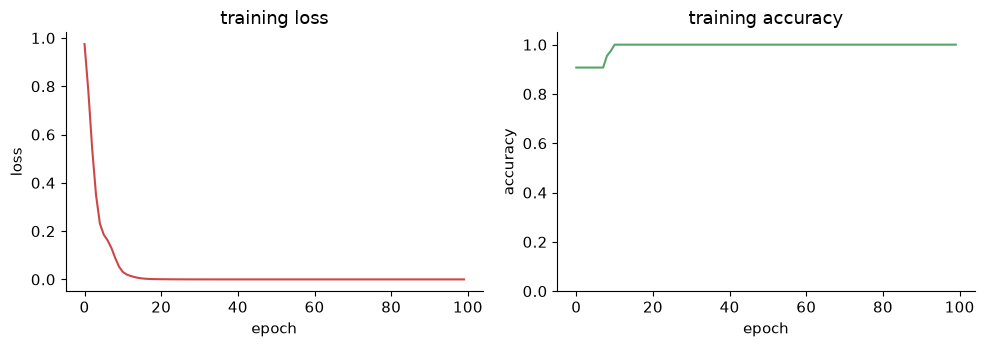

final loss     : 0.0000
final train acc: 1.000


In [4]:
from medical import Polarity, extract
REPORTS = ROOT / 'datasets' / 'iu_xray' / 'indiana_reports.csv'
def _norm(s):
    if not isinstance(s, str): return []
    return [t.strip().lower() for t in re.split(r'[;/,]', s) if t.strip()]
def _weak_label(claim, truth):
    present = any(claim.finding.lower() in t for t in truth)
    if claim.polarity == Polarity.UNCERTAIN: return 'indeterminate'
    if claim.polarity == Polarity.NEGATIVE: return 'supported' if not present else 'contradicted'
    return 'supported' if present else 'contradicted'
def _features(claim, label):
    present_expected = claim.polarity != Polarity.NEGATIVE
    sup = label == 'supported'; con = label == 'contradicted'
    return [0.5, 0.0, 0.0, 0.0,
            float(claim.polarity == Polarity.NEGATIVE),
            float(claim.polarity == Polarity.UNCERTAIN),
            float(sup if present_expected else sup),
            float(con if present_expected else con)]
df = pd.read_csv(REPORTS); xs, ys = [], []
for _, row in df.iterrows():
    truth = _norm(row.get('MeSH')) + _norm(row.get('Problems'))
    text = '\n'.join(f'{s.upper()}: {row[s]}' for s in ('findings', 'impression') if isinstance(row.get(s), str))
    if not text: continue
    for c in extract(text):
        lab = _weak_label(c, truth)
        xs.append(_features(c, lab)); ys.append(STATUS_INDEX[lab])
x = torch.tensor(xs, dtype=torch.float32); y = torch.tensor(ys, dtype=torch.long)
print(f'training rows: {len(x)}')
torch.manual_seed(0); fresh = CalibrationMLP()
opt = torch.optim.Adam(fresh.parameters(), lr=1e-2)
losses, accs = [], []
for ep in range(100):
    logits = fresh(x); loss = F.cross_entropy(logits, y)
    opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        acc = (logits.argmax(1) == y).float().mean().item()
    losses.append(loss.item()); accs.append(acc)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.6))
a1.plot(losses, color='#CF4647'); a1.set_title('training loss'); a1.set_xlabel('epoch'); a1.set_ylabel('loss')
a2.plot(accs, color='#58A569'); a2.set_title('training accuracy'); a2.set_xlabel('epoch'); a2.set_ylabel('accuracy'); a2.set_ylim(0, 1.05)
plt.tight_layout(); plt.show()
print(f'final loss     : {losses[-1]:.4f}')
print(f'final train acc: {accs[-1]:.3f}')

## 6. Live inference on three illustrative claims

In [5]:
from models.calibration import get_model, calibrate
examples = [
    ('Strong SUPPORTED signal',
     [0.90, 0.40, 0.45, 1.0, 0.0, 0.0, 1.0, 0.0],
     'classifier confident present + detector box + support'),
    ('Strong CONTRADICTED signal',
     [0.08, 0.42, 0.00, 0.0, 0.0, 0.0, 0.0, 1.0],
     'classifier confidently absent + no box + conflict'),
    ('Hedged / INDETERMINATE claim',
     [0.52, 0.02, 0.00, 0.0, 0.0, 1.0, 0.0, 0.0],
     '"possible X" + classifier near 0.5'),
]
rows = []
for name, feats, note in examples:
    status, probs = calibrate(feats)
    rows.append({'example': name, 'predicted': status,
                 'p(supported)':     f"{probs['supported']:.3f}",
                 'p(contradicted)':  f"{probs['contradicted']:.3f}",
                 'p(indeterminate)': f"{probs['indeterminate']:.3f}",
                 'signal': note})
pd.DataFrame(rows)

,example,predicted,p(supported),p(contradicted),p(indeterminate),signal
0,Strong SUPPORTED signal,supported,1.000,0.000,0.000,classifier confident present + detector box + ...
1,Strong CONTRADICTED signal,contradicted,0.000,1.000,0.000,classifier confidently absent + no box + conflict
2,Hedged / INDETERMINATE claim,indeterminate,0.000,0.000,1.000,"""possible X"" + classifier near 0.5"


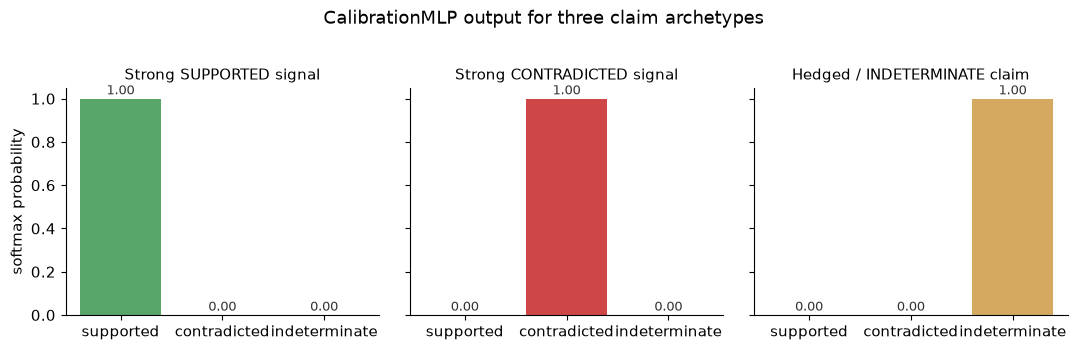

In [6]:
STATUSES = ('supported', 'contradicted', 'indeterminate')
colors = {'supported': '#58A569', 'contradicted': '#CF4647', 'indeterminate': '#D6A961'}
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for ax, (name, feats, _note) in zip(axes, examples):
    _, probs = calibrate(feats)
    vals = [probs[s] for s in STATUSES]
    ax.bar(STATUSES, vals, color=[colors[s] for s in STATUSES])
    ax.set_title(name, fontsize=11); ax.set_ylim(0, 1.05)
    for i, v in enumerate(vals):
        ax.text(i, v + 0.02, f'{v:.2f}', ha='center', fontsize=9, color='#333')
axes[0].set_ylabel('softmax probability')
fig.suptitle('CalibrationMLP output for three claim archetypes', y=1.02)
plt.tight_layout(); plt.show()

## 7. First-layer weight heatmap

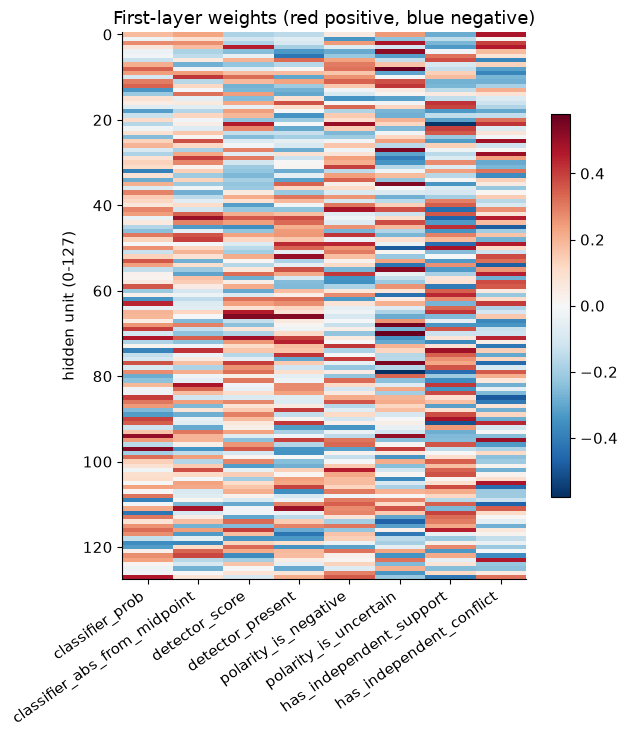

,feature,mean |weight|
0,has_independent_support,0.254
1,has_independent_conflict,0.228
2,polarity_is_uncertain,0.227
3,detector_present,0.203
4,detector_score,0.196
5,classifier_prob,0.192
6,polarity_is_negative,0.189
7,classifier_abs_from_midpoint,0.177


In [7]:
trained = get_model()
W1 = trained.net[0].weight.detach().numpy()
fig, ax = plt.subplots(figsize=(6.5, 7.5))
lim = np.max(np.abs(W1))
im = ax.imshow(W1, cmap='RdBu_r', aspect='auto', vmin=-lim, vmax=lim)
ax.set_xticks(range(8), FEATURE_NAMES, rotation=35, ha='right')
ax.set_ylabel('hidden unit (0-127)')
ax.set_title('First-layer weights (red positive, blue negative)')
plt.colorbar(im, ax=ax, shrink=0.7); plt.tight_layout(); plt.show()
pd.DataFrame({'feature': FEATURE_NAMES,
              'mean |weight|': np.abs(W1).mean(axis=0).round(3),
}).sort_values('mean |weight|', ascending=False).reset_index(drop=True)

## 8. Evaluation on 42 hand labels - test accuracy and friends

Runs the full pipeline (classifier + Grounding-DINO detector + rule verifier + calibration MLP) on each of the 42 claim/image pairs you hand-labelled.

Takes ~10 minutes on CPU - each case runs both vision models on a real X-ray.

In [8]:
from medical.evaluation import _compute_metrics, CaseResult
from graph.build import run_audit
QUEUE = ROOT / 'datasets' / 'iu_xray' / 'labeling_queue.json'
LABELS = ROOT / 'datasets' / 'iu_xray' / 'hand_labels.json'
IMG_DIR = ROOT / 'datasets' / 'iu_xray' / 'images'
queue = {it['claim_id']: it for it in json.loads(QUEUE.read_text())}
labels = json.loads(LABELS.read_text())
results, probs_per_case, true_per_case = [], [], []
for cid, lab in labels.items():
    if lab.get('decision') == 'skipped' or cid not in queue: continue
    it = queue[cid]; p = IMG_DIR / it['image']
    if not p.exists(): continue
    r = run_audit(f"FINDINGS: {it['sentence']}", mode='normal', image_bytes=p.read_bytes())
    v = next((v for v in r.verdicts if any(c.finding == it['finding'] and c.claim_id == v.claim_id for c in r.claims)), None)
    if v is None: continue
    actual = v.status.value
    results.append(CaseResult(name=cid, overall_status=r.overall_hallucination_status,
        per_claim=[{'finding': it['finding'], 'expected': lab['decision'], 'actual': actual, 'matched': actual == lab['decision']}],
        recheck_count=r.recheck_count, latency_ms=0.0, needs_human_review=r.needs_human_review))
    cp = v.calibrated_probs or {}
    probs_per_case.append([cp.get('supported', 0.0), cp.get('contradicted', 0.0), cp.get('indeterminate', 0.0)])
    true_per_case.append(STATUS_INDEX[lab['decision']])
m = _compute_metrics(results)
probabilities = np.array(probs_per_case); true_labels = np.array(true_per_case)
pd.DataFrame({
    'metric': ['labels evaluated', 'test accuracy', 'coverage', 'abstention rate',
               'precision supported', 'recall supported', 'F1 supported',
               'precision contradicted', 'recall contradicted', 'F1 contradicted',
               'precision indeterminate', 'recall indeterminate', 'F1 indeterminate'],
    'value': [m.n_claims, f'{m.accuracy:.3f}  ({int(m.accuracy*m.n_claims)} / {m.n_claims})',
              f'{m.coverage:.3f}', f'{m.abstention_rate:.3f}',
              f"{m.precision['supported']:.3f}",     f"{m.recall['supported']:.3f}",     f"{m.f1['supported']:.3f}",
              f"{m.precision['contradicted']:.3f}",  f"{m.recall['contradicted']:.3f}",  f"{m.f1['contradicted']:.3f}",
              f"{m.precision['indeterminate']:.3f}", f"{m.recall['indeterminate']:.3f}", f"{m.f1['indeterminate']:.3f}"],
}).set_index('metric')

D:\STUDY\DL Lab\Project\VisionGuard-Medical\.venv\Lib\site-packages\langgraph\checkpoint\base\__init__.py:18: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer


,value
metric,
labels evaluated,42
test accuracy,0.786 (33 / 42)
coverage,0.952
abstention rate,0.048
precision supported,0.775
recall supported,1.000
F1 supported,0.873
precision contradicted,0.000
recall contradicted,0.000


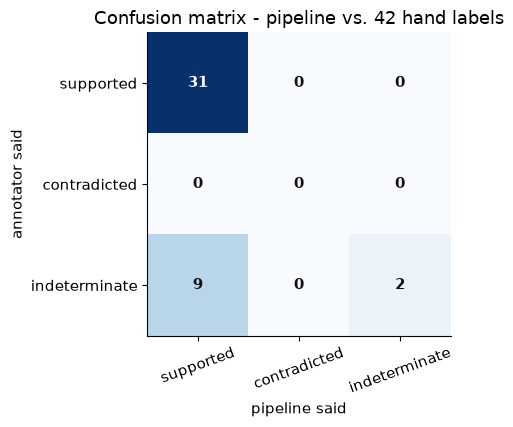

In [9]:
mat = np.array([[m.confusion[r][c] for c in STATUSES] for r in STATUSES])
fig, ax = plt.subplots(figsize=(5.5, 4.4))
im = ax.imshow(mat, cmap='Blues')
ax.set_xticks(range(3), STATUSES, rotation=20); ax.set_yticks(range(3), STATUSES)
ax.set_xlabel('pipeline said'); ax.set_ylabel('annotator said')
ax.set_title('Confusion matrix - pipeline vs. 42 hand labels')
for i in range(3):
    for j in range(3):
        ax.text(j, i, mat[i, j], ha='center', va='center',
                color='white' if mat[i, j] > mat.max()*0.5 else '#111', fontweight='bold')
plt.tight_layout(); plt.show()

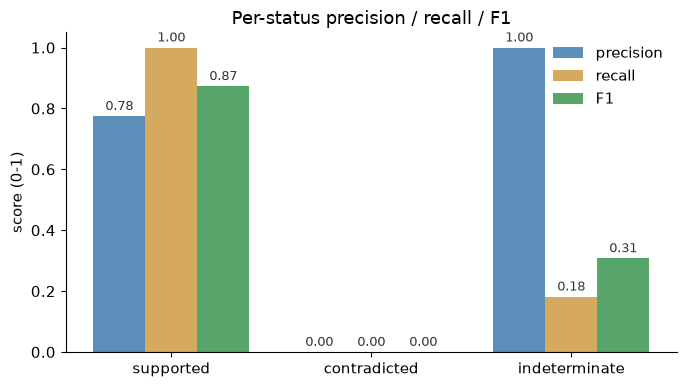

In [10]:
x_pos = np.arange(len(STATUSES)); w = 0.26
prec = [m.precision[s] for s in STATUSES]
rec  = [m.recall[s]    for s in STATUSES]
f1_  = [m.f1[s]        for s in STATUSES]
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(x_pos - w, prec, w, label='precision', color='#5B8FB9')
ax.bar(x_pos,     rec,  w, label='recall',    color='#D6A961')
ax.bar(x_pos + w, f1_,  w, label='F1',        color='#58A569')
ax.set_xticks(x_pos, STATUSES); ax.set_ylim(0, 1.05)
ax.set_ylabel('score (0-1)'); ax.set_title('Per-status precision / recall / F1')
ax.legend(frameon=False, loc='upper right')
for i, (p, r_, f) in enumerate(zip(prec, rec, f1_)):
    for off, v in zip((-w, 0, w), (p, r_, f)):
        ax.text(i + off, v + 0.02, f'{v:.2f}', ha='center', fontsize=9, color='#333')
plt.tight_layout(); plt.show()

## 9. ROC curves and AUC (one-vs-rest)

AUC-ROC measures how well the model separates one class from the rest across every threshold. 1.0 = perfect, 0.5 = random. For 3-class we plot one curve per class.

Caveat: 42 cases with 0 contradicted labels is tiny. AUC for "contradicted" is undefined; others have wide confidence intervals.

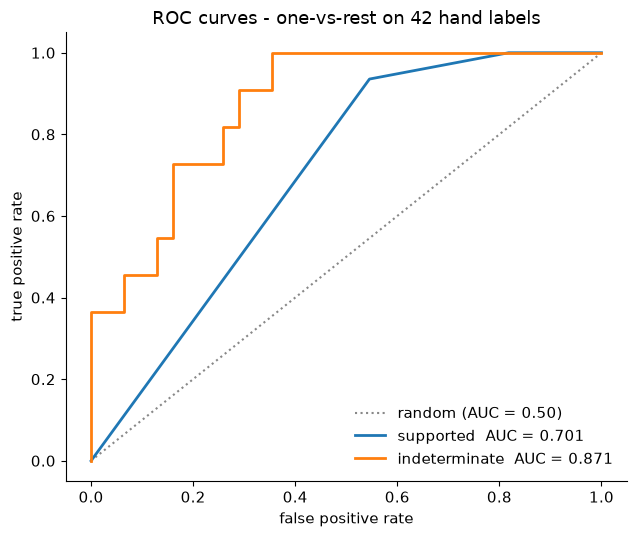

,class,AUC,positive samples
0,supported,0.701,31
1,contradicted,undefined (0 positives),0
2,indeterminate,0.871,11


In [11]:
from sklearn.metrics import roc_curve, auc
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.plot([0, 1], [0, 1], ':', color='#888', label='random (AUC = 0.50)')
per_class_auc = {}
for i, status in enumerate(STATUSES):
    y_true_bin = (true_labels == STATUS_INDEX[status]).astype(int)
    if y_true_bin.sum() == 0 or y_true_bin.sum() == len(y_true_bin):
        per_class_auc[status] = None; continue
    y_score = probabilities[:, i]
    fpr, tpr, _ = roc_curve(y_true_bin, y_score)
    a = auc(fpr, tpr); per_class_auc[status] = a
    ax.plot(fpr, tpr, lw=2, label=f'{status}  AUC = {a:.3f}')
ax.set_xlabel('false positive rate'); ax.set_ylabel('true positive rate')
ax.set_title('ROC curves - one-vs-rest on 42 hand labels')
ax.legend(loc='lower right', frameon=False); plt.tight_layout(); plt.show()
pd.DataFrame({
    'class': STATUSES,
    'AUC': [f'{per_class_auc[s]:.3f}' if per_class_auc[s] is not None else 'undefined (0 positives)' for s in STATUSES],
    'positive samples': [int((true_labels == STATUS_INDEX[s]).sum()) for s in STATUSES],
})